# CredResolve — Reproducible Collections Analysis

**Purpose:** independently reconstruct payment recovery, quantify data reliability, and separate observed facts from unsupported causal claims.

**Run from project root** after installing `requirements.txt`. This notebook reads the supplied SQLite database and curated CSV outputs. It does not overwrite source data.

**Guardrails:** payment ID is the transaction key; references are quality attributes only. August 2026 is partial. Current account balances are not historical denominators. Channel associations are observational, not conversion rates.

In [1]:
from pathlib import Path
import sqlite3, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
ROOT = next((p.resolve() for p in candidates if (p / "data/processed/collections.db").exists()), Path.cwd().resolve())
DB = ROOT / "data/processed/collections.db"
OUT = ROOT / "outputs"
assert DB.exists(), f"Database not found: {DB.resolve()}"
con = sqlite3.connect(DB)
print("Project:", ROOT.resolve())


Project: /mnt/data/credresolve_build/collections_analytics_project


## 1. Source inventory and coverage

In [2]:
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", con)
source_tables = [t for t in tables.name if not t.startswith("raw_") and t not in {"sqlite_sequence"}]
source_tables


['account_status_history',
 'accounts',
 'agent_sessions',
 'agents',
 'borrowers',
 'call_attempts',
 'call_dispositions',
 'calls',
 'campaigns',
 'complaints',
 'daily_targeting',
 'data_dictionary',
 'field_visits',
 'payments',
 'promises_to_pay',
 'sms_events',
 'vendor_telephony',
 'whatsapp_events']

In [3]:
inventory = []
for table in ["raw_payments","raw_accounts","raw_agents","raw_calls","raw_call_attempts",
               "raw_call_dispositions","raw_daily_targeting","raw_campaigns",
               "raw_promises_to_pay","raw_sms_events","raw_whatsapp_events","raw_field_visits"]:
    try:
        n = pd.read_sql_query(f'SELECT COUNT(*) AS n FROM "{table}"', con).iloc[0,0]
        inventory.append({"table":table,"rows":int(n)})
    except Exception:
        pass
inventory = pd.DataFrame(inventory)
inventory


,table,rows
0,raw_payments,25500
1,raw_accounts,30000
2,raw_agents,30000
3,raw_calls,91350
4,raw_call_attempts,120000
5,raw_call_dispositions,35000
6,raw_daily_targeting,45000
7,raw_campaigns,120
8,raw_promises_to_pay,18000
9,raw_sms_events,45000


## 2. Payment reconstruction — payment_id, not payment_reference

In [4]:
raw = pd.read_sql_query("SELECT * FROM raw_payments", con)
raw["amount"] = pd.to_numeric(raw["amount"], errors="coerce")
raw["payment_id"] = raw.payment_id.astype("string")
keyed = raw[raw.payment_id.notna() & raw.payment_id.str.strip().ne("")].copy()
conflicts = (keyed.groupby("payment_id").agg(
    source_rows=("payment_id","size"),
    account_variants=("account_id","nunique"),
    amount_variants=("amount","nunique"),
    status_variants=("payment_status","nunique"),
    event_time_variants=("event_at","nunique")
).reset_index())
conflicts["conflict"] = conflicts[["account_variants","amount_variants","status_variants","event_time_variants"]].gt(1).any(axis=1)
conflict_ids = set(conflicts.loc[conflicts.conflict,"payment_id"])
print("Raw rows:",len(raw),"; keyed rows:",len(keyed),"; unique IDs:",keyed.payment_id.nunique(),"; conflicting IDs:",len(conflict_ids))
assert len(conflict_ids)==0, "Stop: conflicting payment_id groups require manual review."


Raw rows: 25500 ; keyed rows: 25500 ; unique IDs: 25000 ; conflicting IDs: 0


In [5]:
# Coalesce repeated payment_id rows only after conflict checks. MAX is safe here because
# conflicting non-null values were screened; it selects a populated value where duplicates contain nulls.
canonical = keyed.groupby("payment_id",as_index=False).agg({
    "account_id":"first","borrower_id":"first","event_at":"first",
    "payment_reference":"first","amount":"first","payment_status":"first",
    "payment_method":"first","provider_id":"first"
})
golden = canonical[(canonical.payment_status.str.upper()=="SUCCESS") & (canonical.amount>0)].copy()
print("Golden rows:",len(golden))
print("Gross recovery ₹:",round(golden.amount.sum(),2))
print("Unique paying accounts:",golden.account_id.nunique())
assert len(golden)==17534
assert round(golden.amount.sum(),2)==1315583964.64


Golden rows: 17534
Gross recovery ₹: 1315583964.64
Unique paying accounts: 13284


## 3. Monthly recovery and the 11% claim

In [6]:
golden["month"] = pd.to_datetime(golden.event_at,errors="coerce").dt.to_period("M").astype(str)
monthly = golden.groupby("month").agg(
    successful_payment_count=("payment_id","nunique"),
    unique_paying_accounts=("account_id","nunique"),
    successful_recovery_amount=("amount","sum")
).reset_index().sort_values("month")
monthly["recovery_cr"] = monthly.successful_recovery_amount/1e7
monthly["mom_change_pct"] = monthly.successful_recovery_amount.pct_change()*100
monthly


,month,successful_payment_count,unique_paying_accounts,successful_recovery_amount,recovery_cr,mom_change_pct
0,2026-01,2464,2374,1.872291e+08,18.722913,NaN
1,2026-02,2268,2173,1.701425e+08,17.014245,-9.126077
2,2026-03,2524,2419,1.889124e+08,18.891237,11.031885
3,2026-04,2406,2304,1.751380e+08,17.513804,-7.291386
4,2026-05,2449,2344,1.842503e+08,18.425028,5.202887
5,2026-06,2366,2286,1.755597e+08,17.555973,-4.716710
6,2026-07,2441,2335,1.872423e+08,18.724227,6.654452
7,2026-08,616,608,4.710970e+07,4.710970,-74.840245


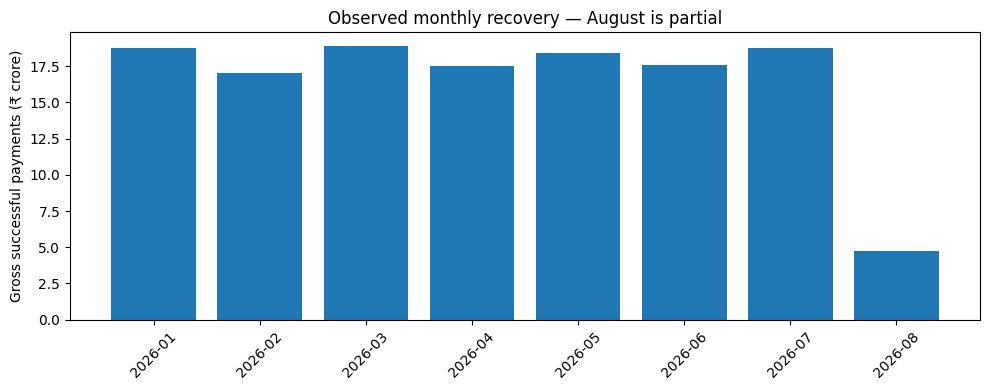

In [7]:
fig, ax = plt.subplots(figsize=(10,4))
ax.bar(monthly.month, monthly.recovery_cr)
ax.set_ylabel("Gross successful payments (₹ crore)")
ax.set_title("Observed monthly recovery — August is partial")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


**Interpretation:** March is approximately +11.03% versus February, but other full months move in both directions. August is only through 8 August and must not be compared with complete months. There is no governed eligible-balance denominator or complete 12-month payment history; therefore the reported 11% improvement is **not verifiable**. Gross recovery is not incremental lift.

## 4. Identity and event-key reliability

In [8]:
accounts = pd.read_sql_query("SELECT * FROM raw_accounts", con)
pay_identity = golden[["payment_id","account_id","borrower_id"]].merge(
    accounts[["account_id","borrower_id"]].rename(columns={"borrower_id":"master_borrower_id"}),
    on="account_id",how="left")
pay_identity["identity_status"] = np.select(
    [pay_identity.borrower_id.isna() | pay_identity.master_borrower_id.isna(),
     pay_identity.borrower_id.eq(pay_identity.master_borrower_id)],
    ["MISSING","MATCH"],default="MISMATCH")
pay_identity.identity_status.value_counts(dropna=False).rename_axis("status").to_frame("payments")


,payments
status,
MISMATCH,17279
MISSING,254
MATCH,1


In [9]:
# Event-key diagnostics: inspect IDs that repeat across accounts before attempting joins.
for table, idcol in [("raw_call_attempts","call_id"),("raw_calls","call_id"),("raw_call_dispositions","call_id"),
                     ("raw_sms_events","message_id"),("raw_whatsapp_events","message_id")]:
    d = pd.read_sql_query(f'SELECT "{idcol}", account_id FROM "{table}"', con)
    stats = d.groupby(idcol).account_id.nunique(dropna=True)
    print(table, "rows",len(d),"unique IDs",d[idcol].nunique(),"IDs spanning >1 account",int((stats>1).sum()))


raw_call_attempts rows 120000 unique IDs 66244 IDs spanning >1 account 34747
raw_calls rows 91350 unique IDs 90000 IDs spanning >1 account 0
raw_call_dispositions rows 35000 unique IDs 28971 IDs spanning >1 account 5282


raw_sms_events rows 45000 unique IDs 27001 IDs spanning >1 account 12354
raw_whatsapp_events rows 60600 unique IDs 34831 IDs spanning >1 account 16818


## 5. Campaign date integrity

In [10]:
target = pd.read_sql_query("SELECT * FROM raw_daily_targeting", con)
campaigns = pd.read_sql_query("SELECT * FROM raw_campaigns", con)
t = target.merge(campaigns[["campaign_id","start_at","end_at"]],on="campaign_id",how="left")
t["target_date"] = pd.to_datetime(t.target_date,errors="coerce").dt.date
t["start_date"] = pd.to_datetime(t.start_at,errors="coerce").dt.date
t["end_date"] = pd.to_datetime(t.end_at,errors="coerce").dt.date
t["date_status"] = np.select([t.start_date.isna() | t.end_date.isna(),t.target_date<t.start_date,t.target_date>t.end_date],
                              ["NO_CAMPAIGN_MATCH","BEFORE_START","AFTER_END"],default="WITHIN_DATES")
summary = t.date_status.value_counts(dropna=False).to_frame("rows")
summary["pct"] = summary.rows/len(t)*100
summary


,rows,pct
date_status,,
AFTER_END,20886,46.413333
BEFORE_START,15253,33.895556
WITHIN_DATES,8861,19.691111


## 6. Channel evidence — association, not conversion

In [11]:
assoc_path = OUT / "channel_payment_association_maturity_adjusted.csv"
if assoc_path.exists():
    channel_assoc = pd.read_csv(assoc_path)
    display(channel_assoc)
else:
    print("No maturity-adjusted association output found.")


,channel,window_days,mature_exposed_accounts,accounts_with_subsequent_payment,observed_rate_pct,interpretation
0,call_attempts,7,29371,1907,6.49,Observational account-level association; popul...
1,call_attempts,30,29034,5674,19.54,Observational account-level association; popul...
2,calls,7,28264,1498,5.30,Observational account-level association; popul...
3,calls,30,27685,4647,16.79,Observational account-level association; popul...
4,dispositions,7,20244,630,3.11,Observational account-level association; popul...
5,dispositions,30,19041,2156,11.32,Observational account-level association; popul...
6,sms,7,22911,766,3.34,Observational account-level association; popul...
7,sms,30,21716,2645,12.18,Observational account-level association; popul...
8,whatsapp,7,25658,974,3.80,Observational account-level association; popul...
9,whatsapp,30,24629,3359,13.64,Observational account-level association; popul...


These populations differ by source and overlap across channels. A payment after a channel event is not proof that the channel caused the payment. No event-to-payment attribution key or randomized assignment is available. Do not label these figures channel conversion.

## 7. Evidence ledger and decision

In [12]:
evidence = pd.DataFrame([
 {"conclusion":"17,534 successful positive payment IDs; ₹131.56 Cr gross","classification":"FACT","confidence":"High, subject to payment_id stability confirmation"},
 {"conclusion":"Only Jan–Aug 2026 payment coverage; August partial","classification":"FACT","confidence":"High"},
 {"conclusion":"Reported 11% sustained improvement","classification":"NOT VERIFIABLE","confidence":"Low / insufficient data"},
 {"conclusion":"Campaign targeting dates align with campaign windows for only ~19.69% of rows","classification":"FACT","confidence":"High, date-only comparison"},
 {"conclusion":"Any one channel caused higher recovery","classification":"HYPOTHESIS","confidence":"Not identified by observational extracts"},
])
evidence


,conclusion,classification,confidence
0,"17,534 successful positive payment IDs; ₹131.5...",FACT,"High, subject to payment_id stability confirma..."
1,Only Jan–Aug 2026 payment coverage; August par...,FACT,High
2,Reported 11% sustained improvement,NOT VERIFIABLE,Low / insufficient data
3,Campaign targeting dates align with campaign w...,FACT,"High, date-only comparison"
4,Any one channel caused higher recovery,HYPOTHESIS,Not identified by observational extracts


### Decision
Do not release the full ₹10 Cr to a channel based on these extracts. Run a pre-registered, account-level randomized targeting pilot with stratification by DPD, balance, risk and client; preserve a holdout; measure 30/60-day incremental net recovery per eligible account; include fully loaded channel and servicing costs; monitor complaints and adverse outcomes. Estimate intention-to-treat lift with confidence intervals and scale only if the lower confidence bound on net benefit exceeds the hurdle rate.

### Limitations / data requests
1. Confirm the exact 12-month reporting window and supply the missing four months.
2. Obtain historical daily eligible balances and account-status snapshots.
3. Obtain channel/campaign assignment IDs, stable interaction IDs and payment attribution rules.
4. Obtain cost, agent-hour, vendor and telephony billing data.
5. Confirm processor guarantees for `payment_id` uniqueness and immutability.
6. Reconcile borrower and agent identity crosswalks; do not force-match ambiguous IDs.

In [13]:
con.close()
print("Notebook analysis completed. No raw source tables were modified.")


Notebook analysis completed. No raw source tables were modified.
